<a href="https://colab.research.google.com/github/gamparithika/Capstone_Project/blob/main/CapStone_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Upload your Framingham CSV dataset


Saving CHD_preprocessed.csv to CHD_preprocessed (1).csv

Dataset loaded successfully!

Dataset shape:
(4133, 16)

First five records:
   male  age  education  currentSmoker  cigsPerDay  BPMeds  prevalentStroke  \
0     1   39          1              0         0.0     0.0                0   
1     0   46          0              0         0.0     0.0                0   
2     1   48          0              1        20.0     0.0                0   
3     0   61          1              1        30.0     0.0                0   
4     0   46          1              1        23.0     0.0                0   

   prevalentHyp  diabetes  totChol  sysBP  diaBP    BMI  heartRate  glucose  \
0             0         0    195.0  106.0   70.0  26.97       80.0     77.0   
1             0         0    250.0  121.0   81.0  28.73       95.0     76.0   
2             0         0    245.0  127.5   80.0  25.34       75.0     70.0   
3             1         0    225.0  150.0   95.0  28.58       65.0    103.0

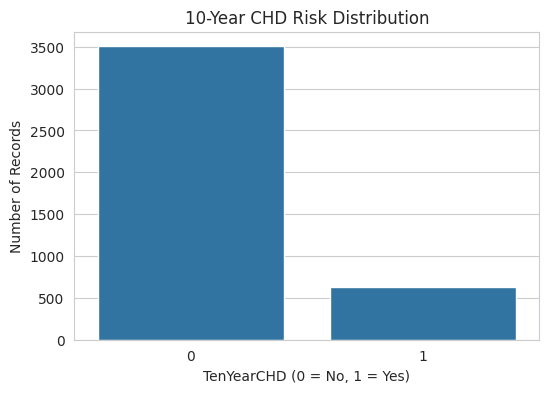

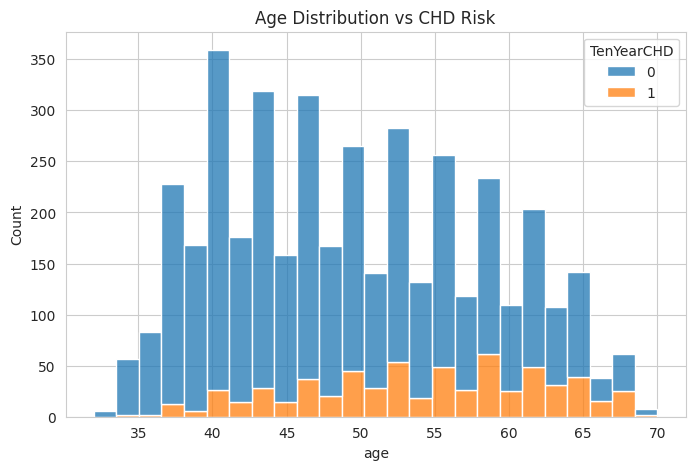

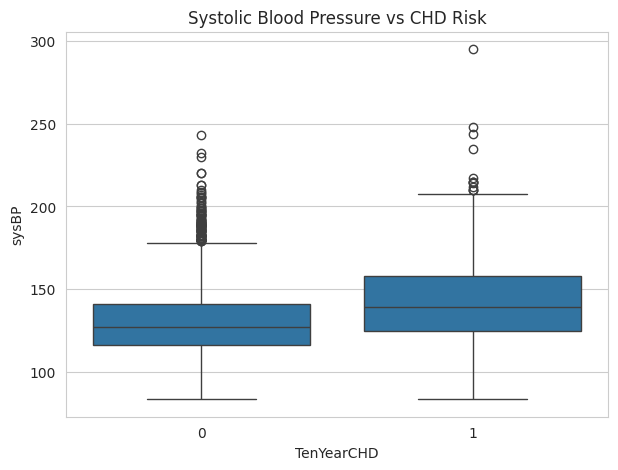

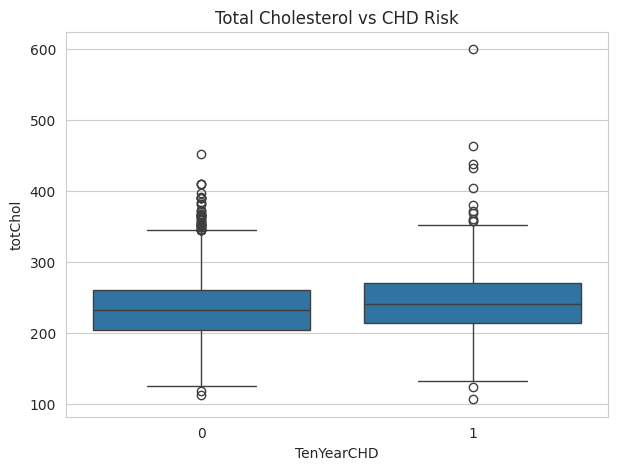

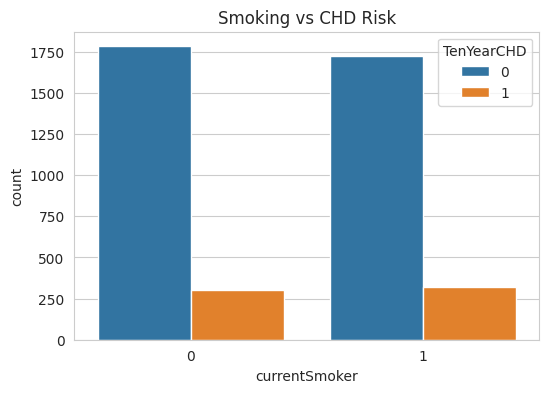

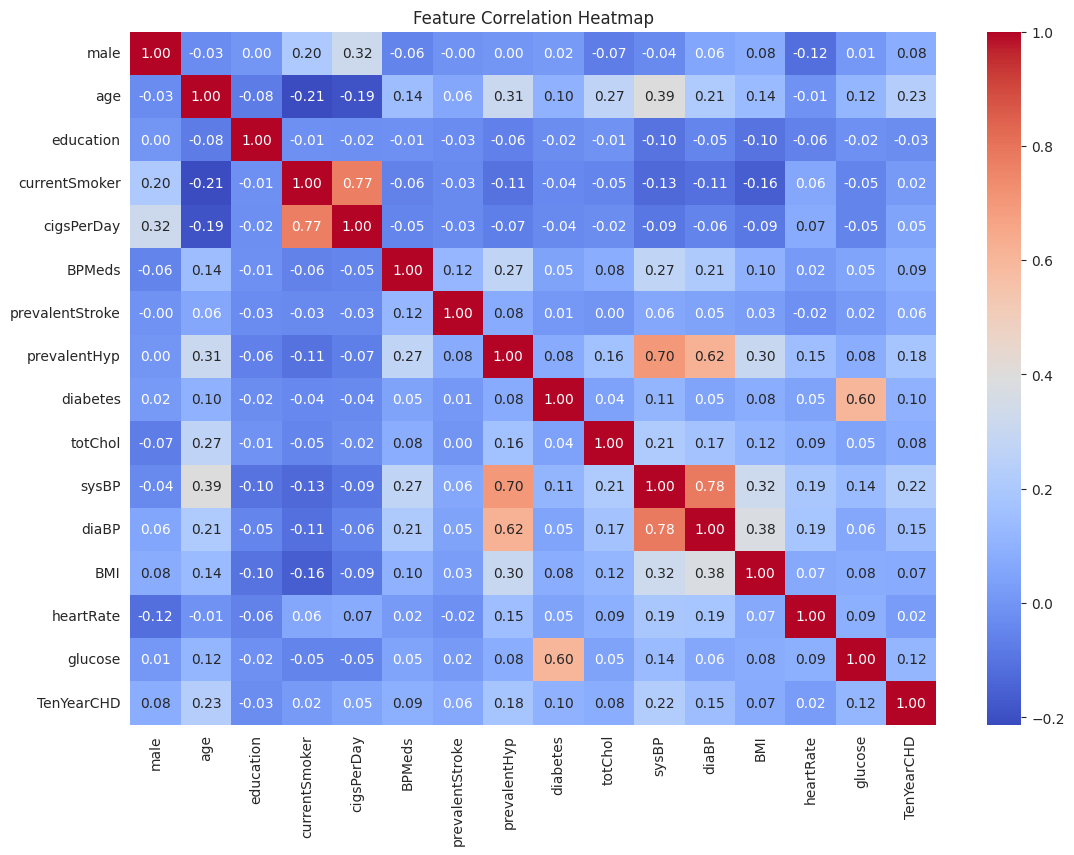


Features used:
['male', 'age', 'education', 'currentSmoker', 'cigsPerDay', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose']

Number of features: 15

Training records: 3306
Testing records: 827

========== BASELINE MODEL ==========
Baseline accuracy: 84.76 %

Training XGBoost model...
Hyperparameter tuning started...
Fitting 5 folds for each of 20 candidates, totalling 100 fits

========== BEST PARAMETERS ==========
{'model__colsample_bytree': np.float64(0.8574323980775167), 'model__gamma': np.float64(0.19993048585762774), 'model__learning_rate': np.float64(0.01886647601058693), 'model__max_depth': 5, 'model__min_child_weight': 7, 'model__n_estimators': 289, 'model__reg_lambda': np.float64(1.3624257381312832), 'model__subsample': np.float64(0.8855158027999261)}

Best cross-validation accuracy: 85.0 %

          XGBOOST RESULTS
Accuracy : 85.61 %
Precision: 81.82 %
Recall   : 7.14 %
F1 Score : 13.14 %
ROC-AUC  : 0.722



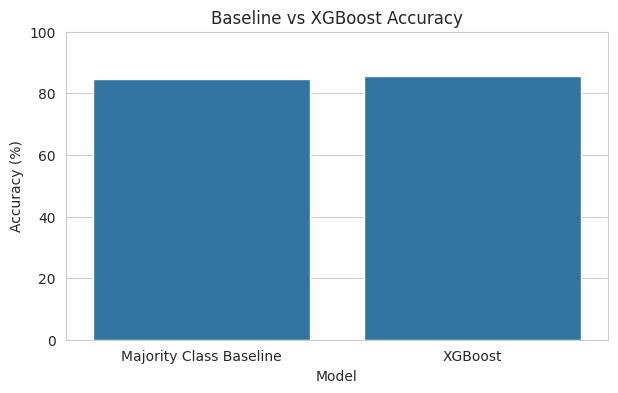

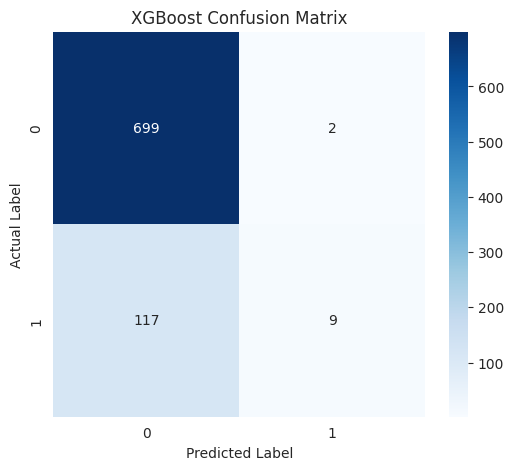


========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

           0       0.86      1.00      0.92       701
           1       0.82      0.07      0.13       126

    accuracy                           0.86       827
   macro avg       0.84      0.53      0.53       827
weighted avg       0.85      0.86      0.80       827



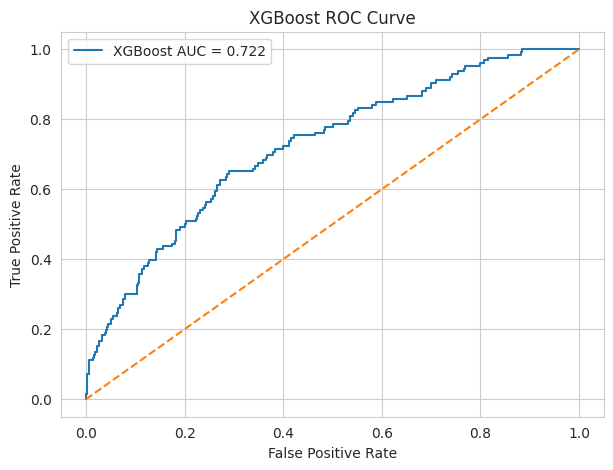


========== FEATURE IMPORTANCE ==========
        Feature  Importance
   prevalentHyp    0.186956
            age    0.133187
          sysBP    0.088769
           male    0.084115
         BPMeds    0.069504
     cigsPerDay    0.060358
        glucose    0.055664
          diaBP    0.050323
        totChol    0.050073
      heartRate    0.047875
  currentSmoker    0.047217
            BMI    0.045619
      education    0.041602
       diabetes    0.038737
prevalentStroke    0.000000


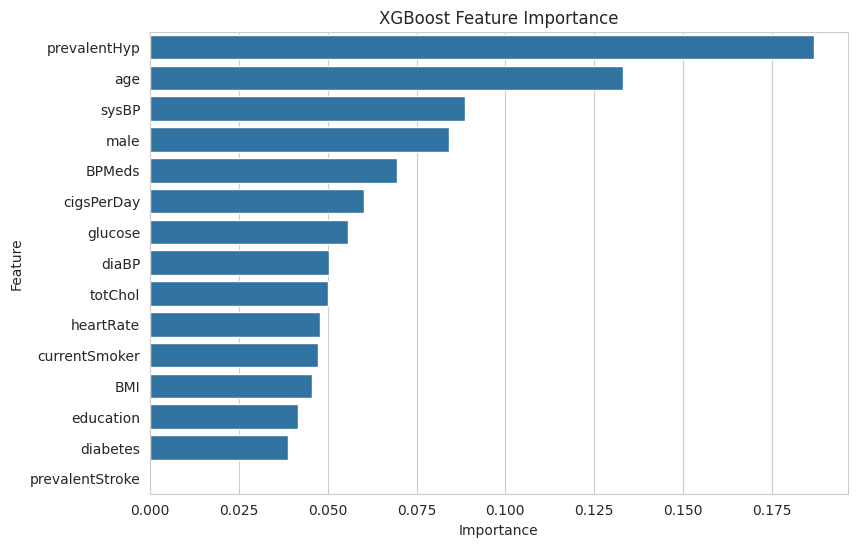


========== NEW PERSON PREDICTION ==========
Model prediction: Lower predicted 10-year CHD risk
Estimated probability of class 1: 14.84 %

         PROJECT SUMMARY
Dataset: Framingham Heart Disease
Algorithm: XGBoost
Total records: 4133
Features: 15
Baseline accuracy: 84.76 %
XGBoost test accuracy: 85.61 %
Precision: 81.82 %
Recall: 7.14 %
F1 Score: 13.14 %
ROC-AUC: 0.722

Project execution completed!

Note: This is an educational risk-prediction model, not a medical diagnosis.


In [ ]:

# EARLY PREDICTION OF CARDIOVASCULAR DISEASE
# USING LIFESTYLE AND HEALTH INDICATORS
#
# DATASET: FRAMINGHAM HEART DISEASE DATASET
# ALGORITHM: XGBOOST
# TARGET: TenYearCHD



# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from google.colab import files

from xgboost import XGBClassifier

from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV,
    StratifiedKFold
)

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

from scipy.stats import randint, uniform

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")


# 2. UPLOAD DATASET

print("Upload your Framingham CSV dataset")

uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("\nDataset loaded successfully!")

print("\nDataset shape:")
print(df.shape)

print("\nFirst five records:")
print(df.head())

print("\nColumn names:")
print(df.columns.tolist())


# 3. CHECK TARGET COLUMN

target = "TenYearCHD"

if target not in df.columns:
    raise ValueError(
        "Target column TenYearCHD not found. "
        "Check the CSV column names."
    )


# 4. DATA CLEANING

print("\nMissing values before cleaning:")

print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())

# Remove exact duplicate records
df = df.drop_duplicates().copy()

# Convert columns to numeric where possible
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove records without target values
df = df.dropna(subset=[target]).copy()

# Target must contain only 0 and 1
df = df[df[target].isin([0, 1])].copy()

df[target] = df[target].astype(int)

print("\nDataset shape after cleaning:")
print(df.shape)

print("\nTarget distribution:")
print(df[target].value_counts())


# 5. TARGET DISTRIBUTION GRAPH

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x=target)

plt.title("10-Year CHD Risk Distribution")
plt.xlabel("TenYearCHD (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")

plt.show()


# 6. EXPLORATORY DATA ANALYSIS

# Age distribution

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="age",
    hue=target,
    bins=25,
    multiple="stack"
)

plt.title("Age Distribution vs CHD Risk")
plt.show()


# Blood pressure

if "sysBP" in df.columns:

    plt.figure(figsize=(7, 5))

    sns.boxplot(
        data=df,
        x=target,
        y="sysBP"
    )

    plt.title("Systolic Blood Pressure vs CHD Risk")
    plt.show()


# Cholesterol

if "totChol" in df.columns:

    plt.figure(figsize=(7, 5))

    sns.boxplot(
        data=df,
        x=target,
        y="totChol"
    )

    plt.title("Total Cholesterol vs CHD Risk")
    plt.show()


# Smoking

if "currentSmoker" in df.columns:

    plt.figure(figsize=(6, 4))

    sns.countplot(
        data=df,
        x="currentSmoker",
        hue=target
    )

    plt.title("Smoking vs CHD Risk")
    plt.show()


# Correlation heatmap

plt.figure(figsize=(13, 9))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Feature Correlation Heatmap")
plt.show()


# 7. FEATURES AND TARGET

X = df.drop(columns=[target])

y = df[target]

feature_columns = X.columns.tolist()

print("\nFeatures used:")
print(feature_columns)

print("\nNumber of features:", len(feature_columns))


# 8. TRAIN-TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))


# 9. BASELINE MODEL

# This model always predicts the majority class.
# It helps us understand whether XGBoost is actually useful.

baseline_model = DummyClassifier(
    strategy="most_frequent"
)

baseline_model.fit(X_train, y_train)

baseline_pred = baseline_model.predict(X_test)

baseline_accuracy = accuracy_score(
    y_test,
    baseline_pred
)

print("\n========== BASELINE MODEL ==========")

print(
    "Baseline accuracy:",
    round(baseline_accuracy * 100, 2),
    "%"
)


# 10. XGBOOST PIPELINE

xgb_pipeline = Pipeline([

    (
        "imputer",
        SimpleImputer(strategy="median")
    ),

    (
        "model",
        XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=1,
            tree_method="hist"
        )
    )

])


# 11. HYPERPARAMETER TUNING

param_grid = {

    "model__n_estimators": randint(100, 500),

    "model__max_depth": randint(2, 7),

    "model__learning_rate": uniform(0.01, 0.19),

    "model__subsample": uniform(0.7, 0.3),

    "model__colsample_bytree": uniform(0.7, 0.3),

    "model__min_child_weight": randint(1, 8),

    "model__gamma": uniform(0, 0.5),

    "model__reg_lambda": uniform(1, 4)
}


cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


random_search = RandomizedSearchCV(

    estimator=xgb_pipeline,

    param_distributions=param_grid,

    n_iter=20,

    scoring="accuracy",

    cv=cv,

    verbose=1,

    random_state=42,

    n_jobs=-1

)


print("\nTraining XGBoost model...")
print("Hyperparameter tuning started...")

random_search.fit(X_train, y_train)


# 12. BEST MODEL

best_model = random_search.best_estimator_

print("\n========== BEST PARAMETERS ==========")

print(random_search.best_params_)

print(
    "\nBest cross-validation accuracy:",
    round(random_search.best_score_ * 100, 2),
    "%"
)


# 13. PREDICTION

y_pred = best_model.predict(X_test)

y_prob = best_model.predict_proba(X_test)[:, 1]


# 14. MODEL EVALUATION

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

auc = roc_auc_score(y_test, y_prob)


print("\n====================================")
print("          XGBOOST RESULTS")
print("====================================")

print("Accuracy :", round(accuracy * 100, 2), "%")

print("Precision:", round(precision * 100, 2), "%")

print("Recall   :", round(recall * 100, 2), "%")

print("F1 Score :", round(f1 * 100, 2), "%")

print("ROC-AUC  :", round(auc, 4))


# 15. COMPARE BASELINE AND XGBOOST

comparison = pd.DataFrame({

    "Model": [
        "Majority Class Baseline",
        "XGBoost"
    ],

    "Accuracy": [
        baseline_accuracy * 100,
        accuracy * 100
    ]

})

print("\n========== MODEL COMPARISON ==========")

print(comparison)


plt.figure(figsize=(7, 4))

sns.barplot(
    data=comparison,
    x="Model",
    y="Accuracy"
)

plt.title("Baseline vs XGBoost Accuracy")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.show()


# 16. CONFUSION MATRIX

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("XGBoost Confusion Matrix")

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()


# 17. CLASSIFICATION REPORT

print("\n========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)


# 18. ROC CURVE

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"XGBoost AUC = {auc:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("XGBoost ROC Curve")

plt.legend()

plt.show()


# 19. FEATURE IMPORTANCE

xgb_model = best_model.named_steps["model"]

importance = pd.DataFrame({

    "Feature": feature_columns,

    "Importance": xgb_model.feature_importances_

}).sort_values(
    by="Importance",
    ascending=False
)

print("\n========== FEATURE IMPORTANCE ==========")

print(importance.to_string(index=False))


plt.figure(figsize=(9, 6))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("XGBoost Feature Importance")

plt.show()


# 20. NEW PERSON PREDICTION

# Example values.
# Change these values to test another person.

new_person = pd.DataFrame([{

    "male": 1,

    "age": 50,

    "education": 2,

    "currentSmoker": 1,

    "cigsPerDay": 10,

    "BPMeds": 0,

    "prevalentStroke": 0,

    "prevalentHyp": 0,

    "diabetes": 0,

    "totChol": 220,

    "sysBP": 130,

    "diaBP": 85,

    "BMI": 25.5,

    "heartRate": 75,

    "glucose": 85

}])


# Match the dataset's exact feature columns

new_person = new_person.reindex(
    columns=feature_columns
)


if new_person.isnull().any().any():

    missing = new_person.columns[
        new_person.isnull().any()
    ].tolist()

    raise ValueError(
        "Please provide values for these features: "
        + str(missing)
    )


# Predict

new_prediction = best_model.predict(new_person)[0]

new_probability = best_model.predict_proba(
    new_person
)[0][1]


print("\n========== NEW PERSON PREDICTION ==========")

if new_prediction == 1:

    print("Model prediction: Higher predicted 10-year CHD risk")

else:

    print("Model prediction: Lower predicted 10-year CHD risk")


print(
    "Estimated probability of class 1:",
    round(new_probability * 100, 2),
    "%"
)


# 21. FINAL PROJECT SUMMARY

print("\n====================================")
print("         PROJECT SUMMARY")
print("====================================")

print("Dataset: Framingham Heart Disease")

print("Algorithm: XGBoost")

print("Total records:", len(df))

print("Features:", len(feature_columns))

print(
    "Baseline accuracy:",
    round(baseline_accuracy * 100, 2),
    "%"
)

print(
    "XGBoost test accuracy:",
    round(accuracy * 100, 2),
    "%"
)

print(
    "Precision:",
    round(precision * 100, 2),
    "%"
)

print(
    "Recall:",
    round(recall * 100, 2),
    "%"
)

print(
    "F1 Score:",
    round(f1 * 100, 2),
    "%"
)

print(
    "ROC-AUC:",
    round(auc, 4)
)

print("\nProject execution completed!")

print(
    "\nNote: This is an educational risk-prediction model, "
    "not a medical diagnosis."
)
